# 04 - The served model: an ensemble of image heads

Notebooks 01-03 build the three staged models and show, twice over, that the sensor input
does not earn its place: the image branch beats fusion both within a session and on a day
the model has never seen. This notebook builds **what the website actually serves** -
several image heads over the one frozen backbone, averaged inside a single graph.

Two measured facts drive it, both from `scripts/experiments.py`:

1. **The image branch beats fusion on an unseen day**, 0.920 against 1.113 days mean
   leave-one-day-out MAE over six training seeds. It wins on 4 of the 6, mean margin 0.193.
2. **Head training is the biggest source of run-to-run variance** here: the seed-to-seed
   spread (+/- 0.086) is as large as the gap between whole architectures. Averaging the
   heads removes it.

`scripts/train_image_ensemble.py` is the same thing as a runnable script, and
`--lodo` re-measures the honest figure.

In [1]:
import sys, warnings
sys.path.insert(0, "../scripts")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
import common as C, datasets as D, models as M
tf.get_logger().setLevel("ERROR")
print("TensorFlow", tf.__version__)

TensorFlow 2.20.0


## 1. Why not just pick the best single head?

The spread between seeds is the whole point. Below are the six leave-one-day-out runs per
branch: the gap between the best and worst image seed is wider than the gap between the
image branch and fusion, so choosing a model on one run would be choosing noise.

In [2]:
import json
exp = json.loads((C.RESULTS / "experiments.json").read_text())["baseline"]
rows = {}
for branch in ("sensor", "image", "fusion"):
    stats = exp["mean_MAE"][branch]
    rows[branch] = {"mean": round(stats["mean"], 3), "std": round(stats["std"], 3),
                    "best": round(min(stats["runs"]), 3), "worst": round(max(stats["runs"]), 3),
                    "ensemble_of_seeds": exp["ensemble_of_seeds_MAE"].get(branch)}
display(pd.DataFrame(rows).T)
print("seeds:", exp["seeds"])
print()
print("image branch beats fusion on",
      sum(1 for i, f in zip(exp["mean_MAE"]["image"]["runs"], exp["mean_MAE"]["fusion"]["runs"])
          if i < f), f"of {len(exp['seeds'])} seeds")

,mean,std,best,worst,ensemble_of_seeds
sensor,2.392,0.106,2.201,2.542,2.3675
image,0.920,0.086,0.809,1.043,0.8558
fusion,1.113,0.179,0.926,1.365,1.0150


seeds: [42, 7, 2026, 13, 99, 404]

image branch beats fusion on 4 of 6 seeds


## 2. The architecture

One frozen MobileNetV3Small, K trainable heads, and a mean taken **inside** the graph - so
the export is still one file with one image input and one scalar output, and the Pi needs
no extra code to average anything.

In [3]:
import train_image_ensemble as TE

df, X, F, y, (tr, va, te) = D.load_all("blocked", "full")
print(f"heads: {len(TE.SEEDS)}   seeds: {list(TE.SEEDS)}")
print(f"backbone output: {F.shape[1]}-d (frozen, cached)")
heads = TE.train_heads(F[tr], y[tr], F[va], y[va], TE.SEEDS)
print(f"trained {len(heads)} heads, {heads[0].count_params():,} parameters each")

heads: 6   seeds: [42, 7, 2026, 13, 99, 404]
backbone output: 576-d (frozen, cached)


trained 6 heads, 181,761 parameters each


## 3. Does averaging actually help, within a session?

In [4]:
single = [C.regression_metrics(y[te], h.predict(F[te], verbose=0)) for h in heads]
ensemble = C.regression_metrics(y[te], TE.ensemble_predict(heads, F[te]))
table = pd.DataFrame(
    [{"model": f"head {i} (seed {s})", **{k: round(m[k], 4) for k in ("MAE", "RMSE", "R2", "WithinHalfDay")}}
     for i, (s, m) in enumerate(zip(TE.SEEDS, single))]
    + [{"model": "ENSEMBLE", **{k: round(ensemble[k], 4) for k in ("MAE", "RMSE", "R2", "WithinHalfDay")}}]
).set_index("model")
display(table)
print(f"best single head MAE {min(m['MAE'] for m in single):.4f}"
      f"   ensemble MAE {ensemble['MAE']:.4f}")

,MAE,RMSE,R2,WithinHalfDay
model,,,,
head 0 (seed 42),0.1680,0.4260,0.9475,0.9631
head 1 (seed 7),0.2028,0.4338,0.9456,0.9557
head 2 (seed 2026),0.1977,0.3822,0.9578,0.9631
head 3 (seed 13),0.3099,0.4728,0.9354,0.7970
head 4 (seed 99),0.2255,0.4218,0.9485,0.9631
head 5 (seed 404),0.2171,0.4325,0.9459,0.9631
ENSEMBLE,0.1447,0.3933,0.9553,0.9631


best single head MAE 0.1680   ensemble MAE 0.1447


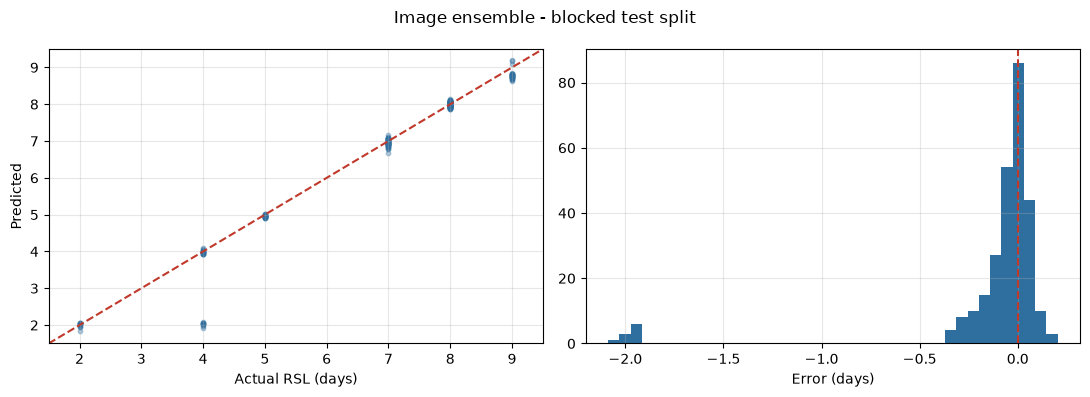

In [5]:
pred = TE.ensemble_predict(heads, F[te])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y[te], pred, s=10, alpha=.35, color="#2f6f9f")
lims = [y[te].min()-.5, y[te].max()+.5]
ax[0].plot(lims, lims, "--", color="#c0392b"); ax[0].set_xlim(lims); ax[0].set_ylim(lims)
ax[0].set_xlabel("Actual RSL (days)"); ax[0].set_ylabel("Predicted"); ax[0].grid(alpha=.3)
ax[1].hist(pred - y[te], bins=40, color="#2f6f9f"); ax[1].axvline(0, color="#c0392b", ls="--")
ax[1].set_xlabel("Error (days)"); ax[1].grid(alpha=.3)
plt.suptitle("Image ensemble - blocked test split"); plt.tight_layout(); plt.show()

## 4. The honest figure: a day it never saw

Within-session numbers on this dataset are largely duplicate retrieval - notebook 03
section 4 shows a 1-NN lookup on *untrained* features scoring 0.081 days there. The
figure the website quotes is this one, produced by
`python scripts/train_image_ensemble.py --lodo`.

In [6]:
lodo = json.loads((C.RESULTS / "image_ensemble_lodo.json").read_text())
display(pd.DataFrame({
    day: {"n": v["held_out_samples"], "true_RSL": v["true_RSL"],
          "ensemble_MAE": round(v["metrics"]["image_ensemble"]["MAE"], 3),
          "mean_single_head_MAE": round(float(np.mean(v["single_head_MAE"])), 3)}
    for day, v in sorted(lodo["folds"].items(), key=lambda kv: int(kv[0]))
}).T)
print(f"heads: {lodo['heads']}")
print("mean across held-out days:", lodo["mean_MAE"])

,n,true_RSL,ensemble_MAE,mean_single_head_MAE
1,111.0,10.0,1.374,1.374
2,647.0,9.0,0.396,0.402
3,628.0,8.0,0.218,0.400
4,327.0,7.0,1.203,1.203
5,162.0,6.0,0.325,0.596
6,653.0,5.0,0.534,1.048
7,360.0,4.0,0.571,0.885
9,170.0,2.0,2.163,2.163


heads: 6
mean across held-out days: {'image_ensemble': 0.8479, 'single_head_average': 1.009}


## 5. What is exported, and what the website loads

`train_image_ensemble.py` (without `--lodo`) assembles the heads onto the frozen backbone,
saves the graph, converts it to TFLite and **re-scores every conversion** on the held-out
rows rather than assuming the conversion was lossless.

In [7]:
rep = json.loads((C.RESULTS / "blocked_full" / "image_ensemble_tflite_report.json").read_text())
display(pd.DataFrame({
    k: {"size_MB": v["size_mb"], "MAE": round(v["metrics"]["MAE"], 4),
        "R2": round(v["metrics"]["R2"], 4),
        "ms/sample": v["latency_ms_per_sample_x86_cpu"], "backend": v["delegate"]}
    for k, v in rep["variants"].items()
}).T)
print("recommended:", rep["recommended"], "- this is the file the website serves")

,size_MB,MAE,R2,ms/sample,backend
float32,8.076,0.1447,0.9553,2.18,xnnpack
float16,4.081,0.1468,0.9549,1.77,xnnpack


recommended: float16 - this is the file the website serves


## 6. What dropping the sensor input buys at serving time

The fusion export could only run on an item with a gas reading, a reading history long
enough for the rolling features, and readings inside the trained envelope. This one needs
a photograph. In the website that moves the trained model from "occasionally usable" to
"usable whenever there is a recent photo".

| | fusion export | image ensemble |
|---|---|---|
| inputs | image + 27 sensor features | image |
| needs a gas sensor | yes | no |
| needs reading history | yes | no |
| needs readings inside the envelope | yes | no |
| within-session MAE | 0.266 d | 0.145 d |
| leave-one-day-out MAE | 1.174 d | 0.848 d |

```bash
pip install tflite-runtime pillow numpy
python scripts/predict_pi.py --image capture.jpg
```

**What it still cannot do.** One food, one camera, one 11-day run. It has never seen a
tomato, another camera, or another room, and the website refuses to score any produce
other than banana for exactly that reason.